In [22]:
import importlib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scripts.paths import RAW_XLSX

# Разведовательный анализ

## Получение данных

In [23]:
df_users = pd.read_excel(RAW_XLSX, sheet_name="Пользователи") # type: ignore
df_payments = pd.read_excel(RAW_XLSX, sheet_name="Платежи") # type: ignore

## Таблица "Пользователи"

In [24]:
df_users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [25]:
df_users[df_users.duplicated(subset=['user_id', 'group'])]

,user_id,group,age,city,device_type


In [26]:
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      1504 non-null   int64
 1   group        1503 non-null   str  
 2   age          1504 non-null   int64
 3   city         1503 non-null   str  
 4   device_type  1504 non-null   str  
dtypes: int64(2), str(3)
memory usage: 58.9 KB


<Axes: xlabel='city', ylabel='share'>

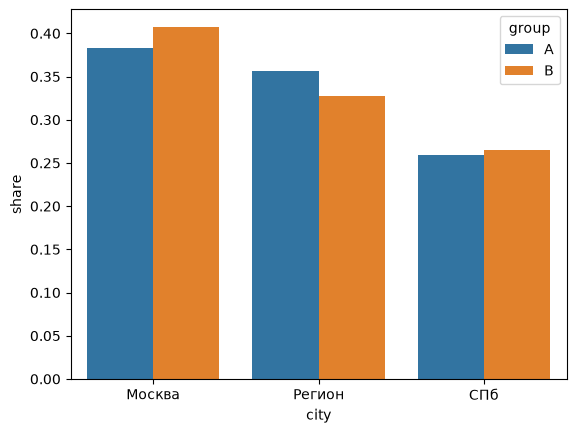

In [27]:
sns.barplot(
    data=df_users.groupby("group", observed=True)["city"].value_counts(normalize=True).rename("share").reset_index(),
    x="city", y="share", hue="group",
)

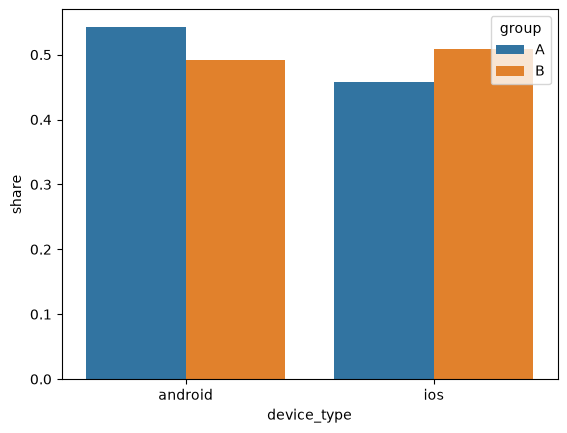

In [28]:
sns.barplot(
    data=df_users.groupby("group", observed=True)["device_type"].value_counts(normalize=True).rename("share").reset_index(),
    x="device_type", y="share", hue="group",
);

## Таблицы "Платежи"

In [29]:
df_payments

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00
...,...,...,...,...,...,...,...
2656,7657,2500.0,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


In [30]:
df_payments[df_payments.duplicated(subset=['payment_id', 'user_id', 'group'])]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


In [31]:
df_payments.describe()

,payment_id,user_id,step1_opened,step2_entered,step3_confirmed,step4_success
count,2661.000000,2660.000000,2661,2256,1719,1522
mean,6433.978579,1760.884211,2024-04-15 17:56:46.854566,2024-04-15 14:21:25.904255,2024-04-15 13:37:05.375218,2024-04-15 12:22:53.534822
min,5001.000000,1001.000000,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
25%,5666.000000,1388.000000,2024-04-08 01:30:00,2024-04-07 22:25:45,2024-04-07 19:01:00,2024-04-07 22:22:00
50%,6331.000000,1762.500000,2024-04-15 15:30:00,2024-04-15 05:12:30,2024-04-15 05:23:00,2024-04-14 23:01:00
75%,6996.000000,2135.250000,2024-04-23 13:25:00,2024-04-23 12:43:00,2024-04-23 14:28:00,2024-04-23 11:49:30
max,99003.000000,9004.000000,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00
std,3203.640974,456.521127,NaN,NaN,NaN,NaN


<Axes: >

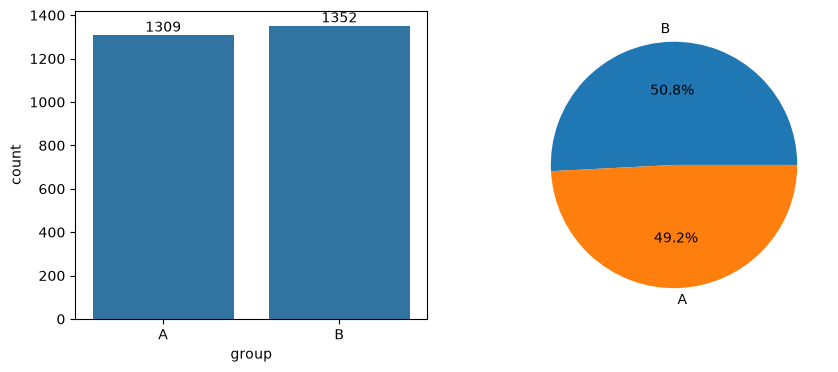

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(df_payments, x="group", ax=ax[0]); ax[0].bar_label(ax[0].containers[0])
df_payments["group"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1], ylabel="")

In [33]:
steps = ["step1_opened", "step2_entered", "step3_confirmed", "step4_success"]

f = df_payments[steps].notna().astype(bool)
viol = pd.DataFrame(
    {f"{steps[i]} без {steps[i-1]}": f[steps[i]] & ~f[steps[i-1]] for i in range(1, len(steps))}
)
print(viol.sum())
invalid = viol.any(axis=1)
print(invalid.sum(), "из", len(df_payments))

step2_entered без step1_opened       0
step3_confirmed без step2_entered    0
step4_success без step3_confirmed    0
dtype: int64
0 из 2661


In [34]:
u = df_users[["user_id", "group"]].drop_duplicates()
p = df_payments[["user_id", "group"]].drop_duplicates()

m = u.merge(p, on=["user_id", "group"], how="outer", indicator=True)
print(m["_merge"].value_counts())
print("полное пересечение:", (m["_merge"] == "both").all())

only_users = m.loc[m["_merge"] == "left_only", ["user_id", "group"]]
only_pay = m.loc[m["_merge"] == "right_only", ["user_id", "group"]]

_merge
both          1501
left_only        3
right_only       2
Name: count, dtype: int64
полное пересечение: False


In [35]:
only_users

,user_id,group
1501,9001.0,NaN
1502,9002.0,A
1503,9003.0,B


In [36]:
only_pay

,user_id,group
10,1010.0,B
1505,NaN,A


# Предобработка

Обработка возраста

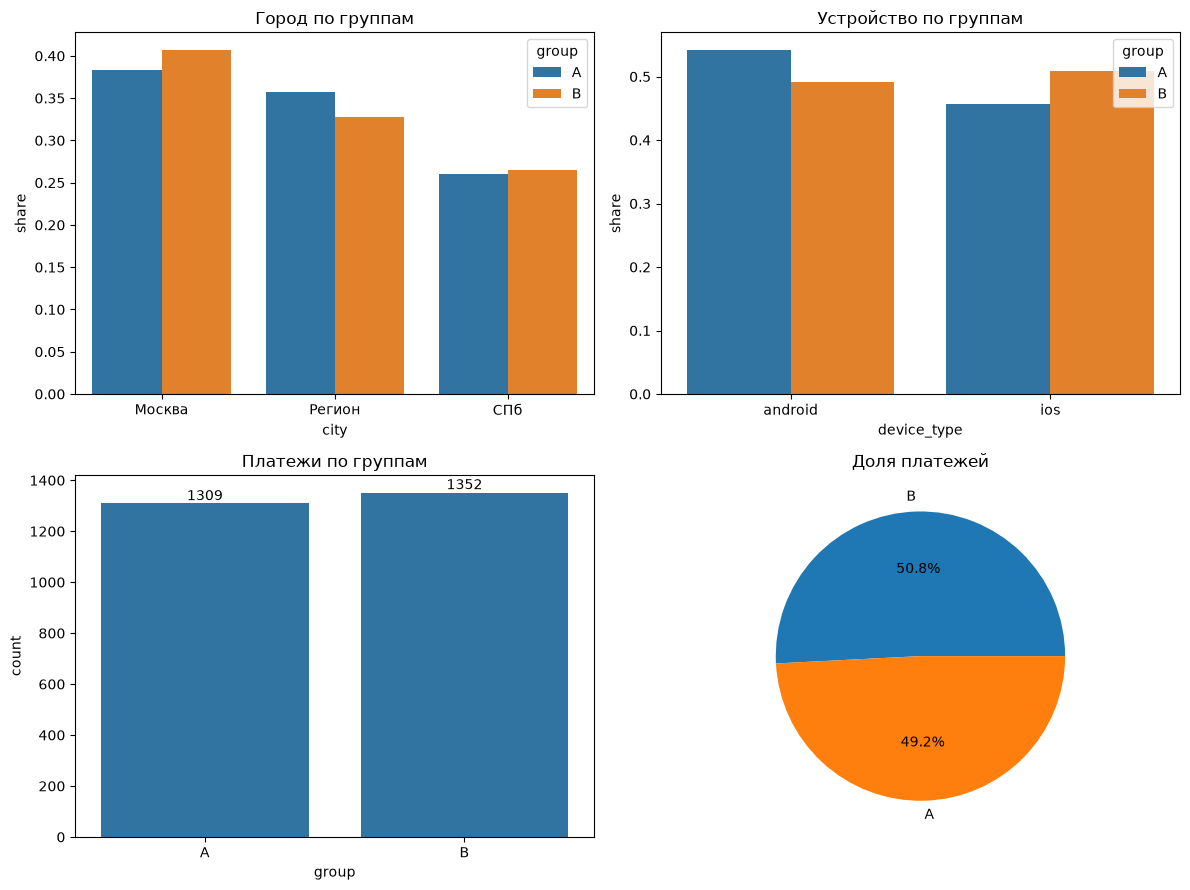

In [37]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

for a, col in zip(ax.flat[:2], ["city", "device_type"]):
    share = df_users.groupby("group", observed=True)[col].value_counts(normalize=True).rename("share").reset_index()
    sns.barplot(share, x=col, y="share", hue="group", ax=a)

sns.countplot(df_payments, x="group", ax=ax[1, 0]); ax[1, 0].bar_label(ax[1, 0].containers[0])
df_payments["group"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1, 1], ylabel="")

ax[0, 0].set_title("Город по группам"); ax[0, 1].set_title("Устройство по группам")
ax[1, 0].set_title("Платежи по группам"); ax[1, 1].set_title("Доля платежей")
fig.tight_layout()